# Homework #4

## Regularization in Machine Learning

This colaboratory contains Homework #4 of the Machine Learning course, which is due **November 05, midnight (23:59 EEST time)**. To complete the homework, extract **(File -> Download .ipynb)** and submit to the course webpage.


## Submission's rules:

1.   Please, submit only .ipynb that you extract from the Colaboratory.
2. Run your homework exercises before submitting (output should be present, preferably restart the kernel and press run all the cells).
3. Do not change the description of tasks in red (even if there is a typo|mistake|etc).
4. Please, make sure to avoid unnecessary long printouts.
5. Each task should be solved right under the question of the task and not elsewhere.
6. Solutions to both regular and bonus exercises should be submitted in one IPYNB file.

Please, steer clear of copying someone else's work. If you discuss assignments with anyone in the course, please, mention their names here:
1. Pooh

##List of Homework's exercises:

1.   [Ex1](#scrollTo=gCUvnKxZXTul) - 3 points
2.   [Ex2](#scrollTo=yLmunCZ9k-G6) - 4 points
3.   [Ex3](#scrollTo=lPdnuVSqeIN2) - 3 points
4.   [Bonus 1](#scrollTo=jdZkblZW7bEp) - up to 4 points (based on quality of presentation)


In [2]:
!pip install -q plotnine
from plotnine import *

import pandas as pd
import numpy as np

import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf

import matplotlib.pyplot as plt
import seaborn as sns

# loading in the cifar10 dataset
from keras.datasets import cifar10
from keras.layers import Input, Conv2D, Activation, Flatten, Dense, MaxPooling2D, BatchNormalization, Dropout
from keras import regularizers, optimizers, Sequential

In [3]:
# Auxiliary functions
def plot_curves(history):
  plt.figure(figsize=(16, 6))

  plt.subplot(1, 2, 1)
  plt.plot(history.history['loss'])
  plt.plot(history.history['val_loss'])
  plt.xlabel('Epoch')
  plt.ylabel('Loss')
  plt.legend(['Training', 'Validation'])
  plt.title('Loss')

  plt.subplot(1, 2, 2)
  plt.plot(history.history['accuracy'])
  plt.plot(history.history['val_accuracy'])
  plt.xlabel('Epoch')
  plt.ylabel('Accuracy')
  plt.legend(['Training', 'Validation'])
  plt.title('Accuracy')

## Homework exercise 1 (3 points): ElasticNet algorithm combines both Ridge and LASSO regression.
<font color='red'> In the class we discussed Ridge and Lasso regression algorithms, which are basically, L2 and L1 regularisations applied to Linear Regression model. ElasticNet is a method that combines both L2 and L1 regularisations under one model. ElasticNet adds both L2 and L1 norms to the error function. Here you should train and visualise ElasticNet model on the toy dataset. </font>


In [3]:
# Let's regenerate training data one more time
example_data = pd.DataFrame({'x':[1,2,3,4,5], 'y':[2,4,5,4,5]})
example_data['x^2'] = example_data.x**2
example_data['x^3'] = example_data.x**3
example_data['x^4'] = example_data.x**4

visualisation_data = pd.DataFrame({'x': np.linspace(start=0, stop=6, num=61),
                          'x^2': np.linspace(start=0, stop=6, num=61)**2,
                          'x^3': np.linspace(start=0, stop=6, num=61)**3,
                          'x^4': np.linspace(start=0, stop=6, num=61)**4})

<font color='red'> **(Homework exercise 1- a)** Train ElasticNet as well as three other regression models (linear, ridge and lasso) using `sklearn` on example data. **(1 point)**. </font>

In [4]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet

# Regularization strength
lambda_ = 1

##### YOUR CODE STARTS #####
# first initialise different regressions
# then fit them to our example_data
# finally predict the visualisation data
lr = LinearRegression()
lr_ridge = Ridge(alpha = lambda_)
lr_lasso = Lasso(alpha = lambda_)
lr_en = ElasticNet(alpha = lambda_, l1_ratio=0.5)

lr.fit(example_data[['x', 'x^2', 'x^3', 'x^4']], example_data[['y']])
lr_ridge.fit(example_data[['x', 'x^2', 'x^3', 'x^4']], example_data[['y']])
lr_lasso.fit(example_data[['x', 'x^2', 'x^3', 'x^4']], example_data[['y']])
lr_en.fit(example_data[['x', 'x^2', 'x^3', 'x^4']], example_data[['y']])

visualisation_data['lr_y'] = lr.predict(visualisation_data[['x', 'x^2', 'x^3', 'x^4']])
visualisation_data['lr_ridge_y'] = lr_ridge.predict(visualisation_data[['x', 'x^2', 'x^3', 'x^4']])
visualisation_data['lr_lass_y'] = lr_lasso.predict(visualisation_data[['x', 'x^2', 'x^3', 'x^4']])
visualisation_data['lr_en_y'] = lr_en.predict(visualisation_data[['x', 'x^2', 'x^3', 'x^4']])

##### YOUR CODE ENDS #####

<font color='red'> **(Homework exercise 1- b)** Visualise all four regression trends (baseline, LASSO, Ridge and ElasticNet) on the same figure. Highlight ElasticNet in <font color='#F1C40F'>yellow</font>, while others in black (linear), red (ridge) and blue (lasso). **(1 point)**. </font>


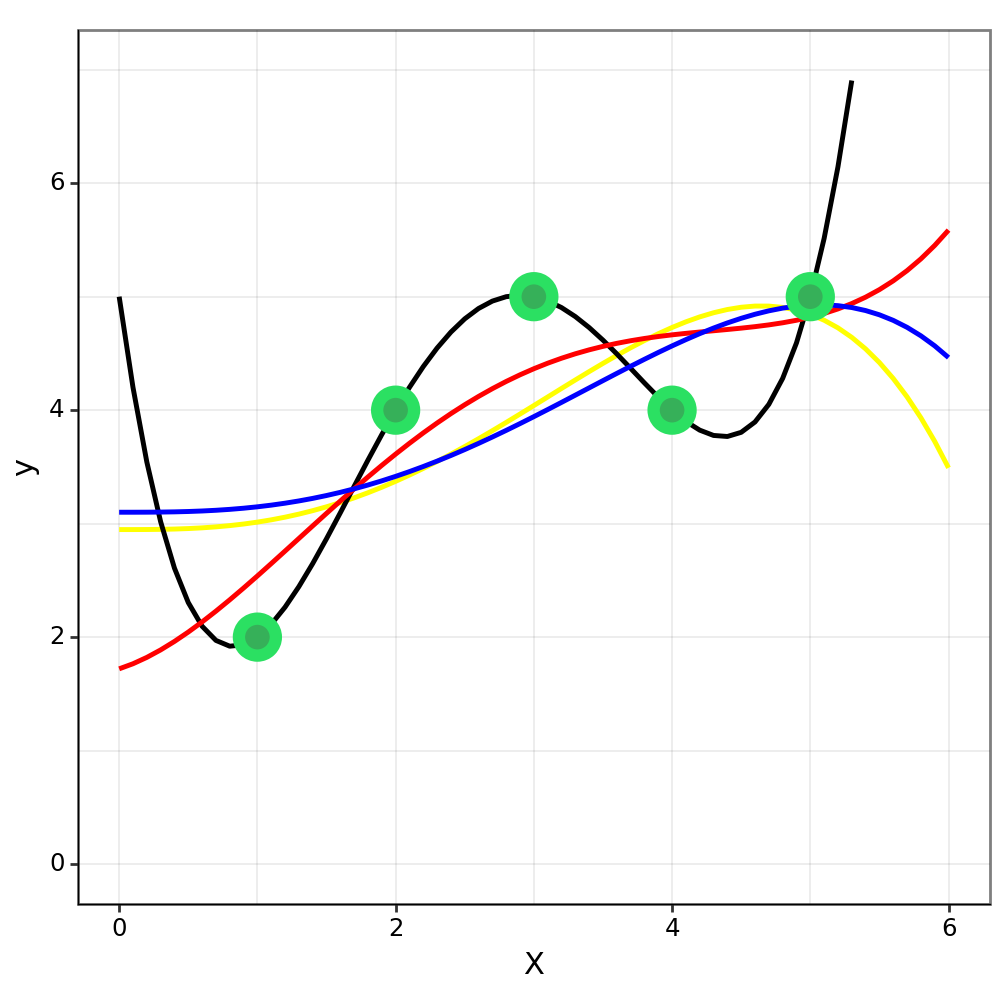

<Figure Size: (500 x 500)>

In [5]:
fig = (
    ggplot(data = example_data,
          mapping = aes(x = 'x', y = 'y')) +
       ##### YOUR CODE STARTS #####
       geom_path(data = visualisation_data, mapping = aes(x = 'x', y = 'lr_en_y'), size = 1, colour = 'yellow') +
       geom_path(data = visualisation_data, mapping = aes(x = 'x', y = 'lr_y'), size = 1, colour = 'black') +
       geom_path(data = visualisation_data, mapping = aes(x = 'x', y = 'lr_ridge_y'), size = 1, colour = 'red') +
       geom_path(data = visualisation_data, mapping = aes(x = 'x', y = 'lr_lass_y'), size = 1, colour = 'blue') +
       ##### YOUR CODE ENDS #####
    geom_point(fill = '#36B059',
               size = 5.0,
               stroke = 2.5,
               colour = '#2BE062',
               shape = 'o') +
    labs(
        title ='',
        x = 'X',
        y = 'y',
    ) +
    xlim(0, 6) +
    ylim(0, 7) +
    theme_bw() +
    theme(figure_size = (5, 5),
          axis_line = element_line(size = 0.5, colour = "black"),
          panel_grid_major = element_line(size = 0.05, colour = "black"),
          panel_grid_minor = element_line(size = 0.05, colour = "black"),
          axis_text = element_text(colour ='black')) +
    guides(size = False)
)
fig


<font color='red'> **(Homework exercise 1- c)** Print out ElasticNet coefficients and intercept, compare it to coefficients and intercept of other regressions. Which one ElasticNet seems to be more similar to? Which parameter in `sklearn.ElasticNet` function is responsible for mixing of L1 and L2 regularisation? **(1 point)**. </font>

In [6]:
##### YOUR CODE STARTS #####
print(f'ElasticNet regression coefficients are: [{lr_en.coef_}, {round(lr_en.intercept_[0], 8)}]')
print(f'Baseline regression: [{lr.coef_}, {round(lr.intercept_[0], 8)}]')
print(f'Ridge regression, forces coefficients to be small: [{lr_ridge.coef_}, {round(lr_ridge.intercept_[0], 8)}]')
print(f'Lasso regression, acts as a feature selection: [{lr_lasso.coef_}, {round(lr_lasso.intercept_[0], 8)}]')
##### YOUR CODE ENDS #####

ElasticNet regression coefficients are: [[ 0.          0.          0.07844547 -0.01265445], 2.9476951]
Baseline regression: [[[-8.75        7.79166667 -2.25        0.20833333]], 5.0]
Ridge regression, forces coefficients to be small: [[[ 0.3882215   0.61877466 -0.20687874  0.0184773 ]], 1.72050238]
Lasso regression, acts as a feature selection: [[ 0.          0.          0.05608653 -0.00829621], 3.1005046]


<font color='red'> Your textual answer goes here: </font>

ElasticNet coefficients and intercept are closer to Lasso regression despite of the l1_ratio parameter being equal to 0.5 (I was expecting an equal resembelement of L1 and L2).

l1_ratio - the ElasticNet mixing parameter, with 0 <= l1_ratio <= 1. For l1_ratio = 0 the penalty is an L2 penalty. For l1_ratio = 1 it is an L1 penalty. For 0 < l1_ratio < 1, the penalty is a combination of L1 and L2. [sklearn.linear_model.ElasticNet](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html)

## Homework exercise 2 (4 points): searching for good dropout rate and lambda
<font color='red'>  </font>

In [4]:
# Keras comes with built-in loaders for common datasets
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

# shorten dataset for quicker training
X_train = X_train[:25000]
y_train = y_train[:25000]

# Normalising values
mu = X_train.mean(axis=(0,1,2)) # finds mean of R, G and B separately
std = X_train.std(axis=(0,1,2)) # same for std
X_train_norm = (X_train - mu)/std
X_test_norm = (X_test - mu)/std

170498071/170498071 [==============================] - 6s 0us/step


<font color='red'>**(Homework exercise 2-a)**
Create a new function `define_model_dropout_lambda`, which takes both dropout and lambda as input parameters. **(0.5 points)**</font>


In [24]:
def define_model_dropout_lambda(dropout_rate, lambda_):
  model = Sequential()
  ##### YOUR CODE STARTS #####
  model.add(Conv2D(32, (3,3), padding='same', kernel_regularizer=regularizers.l2(lambda_), input_shape=(32, 32, 3)))
  model.add(Activation('relu'))
  model.add(Conv2D(32, (3,3), padding='same', kernel_regularizer=regularizers.l2(lambda_)))
  model.add(Activation('relu'))
  model.add(MaxPooling2D(pool_size=(2,2)))
  model.add(Dropout(dropout_rate))

  model.add(Conv2D(64, (3,3), padding='same', kernel_regularizer=regularizers.l2(lambda_)))
  model.add(Activation('relu'))
  model.add(Conv2D(64, (3,3), padding='same', kernel_regularizer=regularizers.l2(lambda_)))
  model.add(Activation('relu'))
  model.add(MaxPooling2D(pool_size=(2,2)))
  model.add(Dropout(dropout_rate))

  model.add(Conv2D(128, (3,3), padding='same', kernel_regularizer=regularizers.l2(lambda_)))
  model.add(Activation('relu'))
  model.add(Conv2D(128, (3,3), padding='same', kernel_regularizer=regularizers.l2(lambda_)))
  model.add(Activation('relu'))
  model.add(MaxPooling2D(pool_size=(2,2)))
  model.add(Dropout(dropout_rate))

  model.add(Flatten())

  model.add(Dense(100, activation='relu', kernel_regularizer=regularizers.l2(lambda_)))
  model.add(Dropout(dropout_rate))

  model.add(Dense(10, activation='softmax'))
  ##### YOUR CODE ENDS #####
  return model

<font color='red'> **(Homework exercise 2- b)** Run K-Fold cross-validation using sklearn. Fill in the gaps to collect validation accuracy scores for each dropout rate and lambda. **(2 points)**. </font>


In [9]:
from sklearn.model_selection import KFold

dropout_rates = [0.0, 0.1, 0.25, 0.5, 0.99]  # feel free to choose other values to loop over
lambdas = [1e-1, 1e-2, 1e-3, 1e-4, 1e-5]  # feel free to choose other values to loop over

# you can collect both accuracy and loss if you like,
# but loss is influenced by the regularisation itself, so maybe less informative
val_fold_acc = np.zeros((len(dropout_rates), len(lambdas)))
val_fold_loss = np.zeros((len(dropout_rates), len(lambdas)))

for i, dropout_rate in enumerate(dropout_rates):
  for j, lambda_ in enumerate(lambdas):
    ##### YOUR CODE STARTS #####
    import gc
    from keras.backend import clear_session
    # 4-fold cross validation
    # Here we are using sklearn Cross Validation Function called KFold
    kf = KFold(n_splits=4, shuffle=True, random_state=111)
    # Do not change these lines, we initialize empty lists
    fold_acc = []
    fold_loss = []
    for train_index, val_index in kf.split(X_train_norm):

      # split data into train_X, train_y and val_X, val_y depending on the fold:
      train_X = X_train_norm[train_index]
      train_y, val_X, val_y = y_train[train_index], X_train_norm[val_index], y_train[val_index]

      # create a neural network with chosen dropout_rate and lambda
      model = define_model_dropout_lambda(dropout_rate, lambda_)

      # compile the model
      model.compile(loss='sparse_categorical_crossentropy', optimizer=optimizers.Adam(learning_rate=0.001), metrics=['accuracy'])

      # fit the neural network on training data
      # number of epochs is tricky, if you choose too little the performance will be unstable
      # if you choose too large, it will take ages to complete...
      # we will remove the output with verbose=0 to avoid long printouts
      model.fit(X_train_norm, y_train, batch_size=16, epochs=10, validation_split=0.2, verbose=0)
      result = model.evaluate(val_X, val_y, verbose=0)

      del model
      clear_session()
      gc.collect()
      # calculate accuracy for this fold and store it in fold_acc
      fold_acc.append(result[0])

      # and loss in fold_loss
      fold_loss.append(result[1])
    ##### YOUR CODE ENDS #####

    print(f'Average validation accuracy for dropout {dropout_rate} and lambda {lambda_} is {np.mean(fold_acc)}')
    val_fold_acc[i][j] = np.mean(fold_acc)
    val_fold_loss[i][j] = np.mean(fold_loss)

Average validation accuracy for dropout 0.0 and lambda 0.1 is 2.302636206150055
Average validation accuracy for dropout 0.0 and lambda 0.01 is 1.7369854152202606
Average validation accuracy for dropout 0.0 and lambda 0.001 is 0.9063304364681244
Average validation accuracy for dropout 0.0 and lambda 0.0001 is 0.5790584534406662
Average validation accuracy for dropout 0.0 and lambda 1e-05 is 0.45128320157527924
Average validation accuracy for dropout 0.1 and lambda 0.1 is 2.302513897418976
Average validation accuracy for dropout 0.1 and lambda 0.01 is 1.8037758469581604
Average validation accuracy for dropout 0.1 and lambda 0.001 is 1.0247162282466888
Average validation accuracy for dropout 0.1 and lambda 0.0001 is 0.6560033559799194
Average validation accuracy for dropout 0.1 and lambda 1e-05 is 0.5221106857061386
Average validation accuracy for dropout 0.25 and lambda 0.1 is 2.3024666905403137
Average validation accuracy for dropout 0.25 and lambda 0.01 is 1.7182433903217316
Average va

<font color='red'> **(Homework exercise 2- c)** Create a heatmap plot that shows validation accuracy or loss (choose for yourself) for different dropout rates and lambdas that you have tried, report the best one. You can check [the docs](https://seaborn.pydata.org/generated/seaborn.heatmap.html) on how to create heatmaps. **(0.5 points)**. </font>


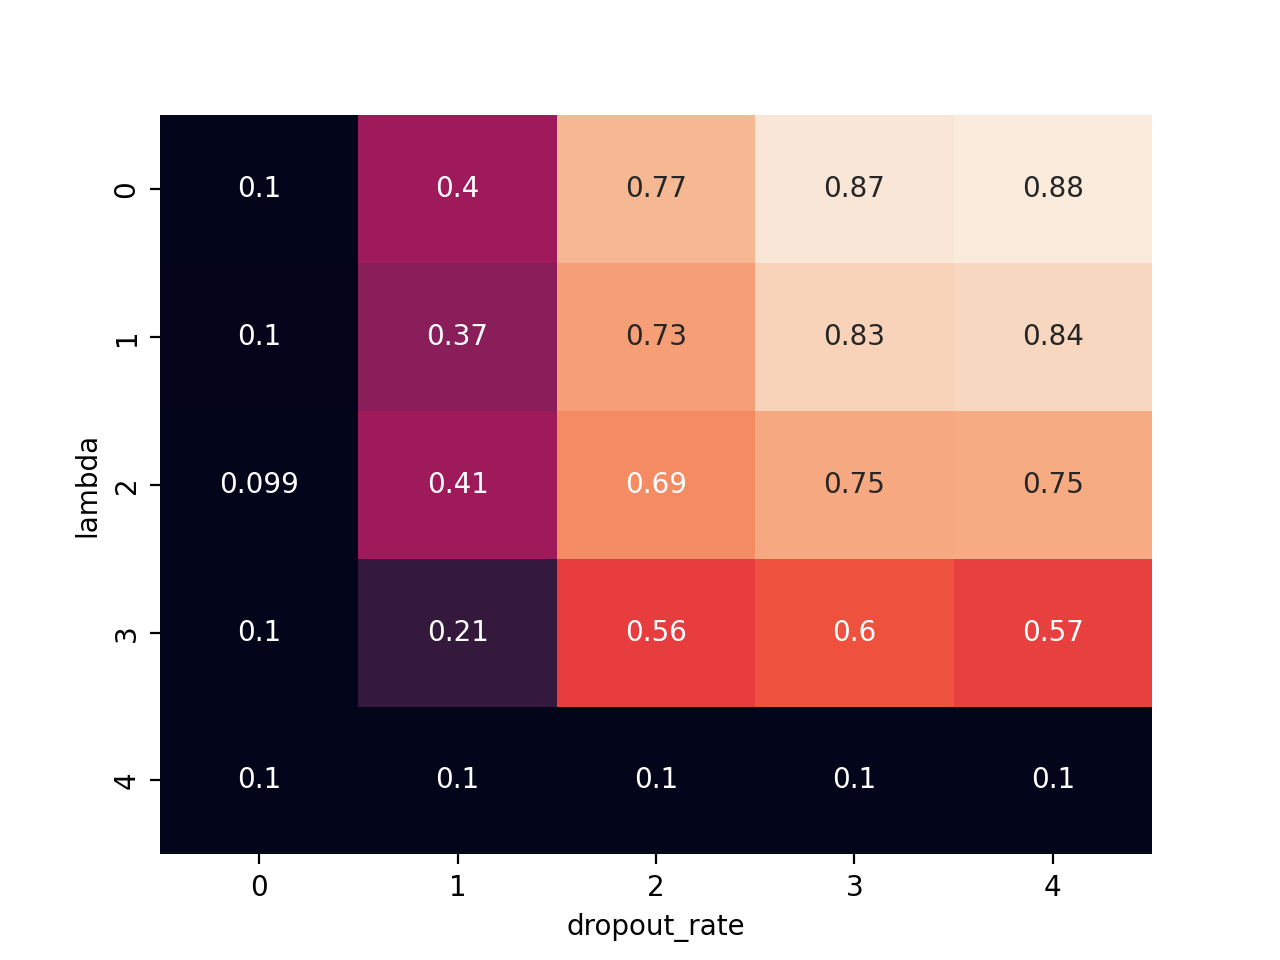

In [13]:
##### YOUR CODE STARTS #####
sns.heatmap(val_fold_loss, annot=True, cbar=False)
plt.xlabel('dropout_rate')
plt.ylabel('lambda')
plt.show()
##### YOUR CODE ENDS #####

According to the above graphs, the best dropout rate seems to be 0 and lambda 0.001 (loss is mininum 0.099).

<font color='red'> **(Homework exercise 2- d)** Re-train the model using the dropout rate and lambda reported in **(c)**. Visualise performance curves and interpret the results. If results did not improve, no need to re-run the process again, just comment on the results. **(1 point)**. </font>

In [16]:
##### YOUR CODE STARTS #####
# Define the model with identified dropout rate and lambda and compile it
dropout_rate_optimal = dropout_rates[0]
lambda_optimal = lambdas[2]

model = define_model_dropout_lambda(dropout_rate_optimal, lambda_optimal)
model.compile(loss='sparse_categorical_crossentropy', optimizer=optimizers.Adam(learning_rate=0.001), metrics=['accuracy'])
# Fit the model; return history object
history = model.fit(X_train_norm, y_train, batch_size=64, epochs=20, validation_split=0.2)
##### YOUR CODE ENDS #####

Epoch 1/20
313/313 [==============================] - 6s 9ms/step - loss: 1.9445 - accuracy: 0.3553 - val_loss: 1.6672 - val_accuracy: 0.4446
Epoch 2/20
313/313 [==============================] - 2s 7ms/step - loss: 1.4972 - accuracy: 0.5106 - val_loss: 1.5220 - val_accuracy: 0.5008
Epoch 3/20
313/313 [==============================] - 2s 7ms/step - loss: 1.3308 - accuracy: 0.5798 - val_loss: 1.2831 - val_accuracy: 0.5920
Epoch 4/20
313/313 [==============================] - 2s 7ms/step - loss: 1.1957 - accuracy: 0.6321 - val_loss: 1.1867 - val_accuracy: 0.6556
Epoch 5/20
313/313 [==============================] - 3s 9ms/step - loss: 1.1056 - accuracy: 0.6752 - val_loss: 1.1233 - val_accuracy: 0.6740
Epoch 6/20
313/313 [==============================] - 2s 7ms/step - loss: 1.0433 - accuracy: 0.7043 - val_loss: 1.1191 - val_accuracy: 0.6788
Epoch 7/20
313/313 [==============================] - 2s 7ms/step - loss: 0.9760 - accuracy: 0.7312 - val_loss: 1.0273 - val_accuracy: 0.7154
Epoch 

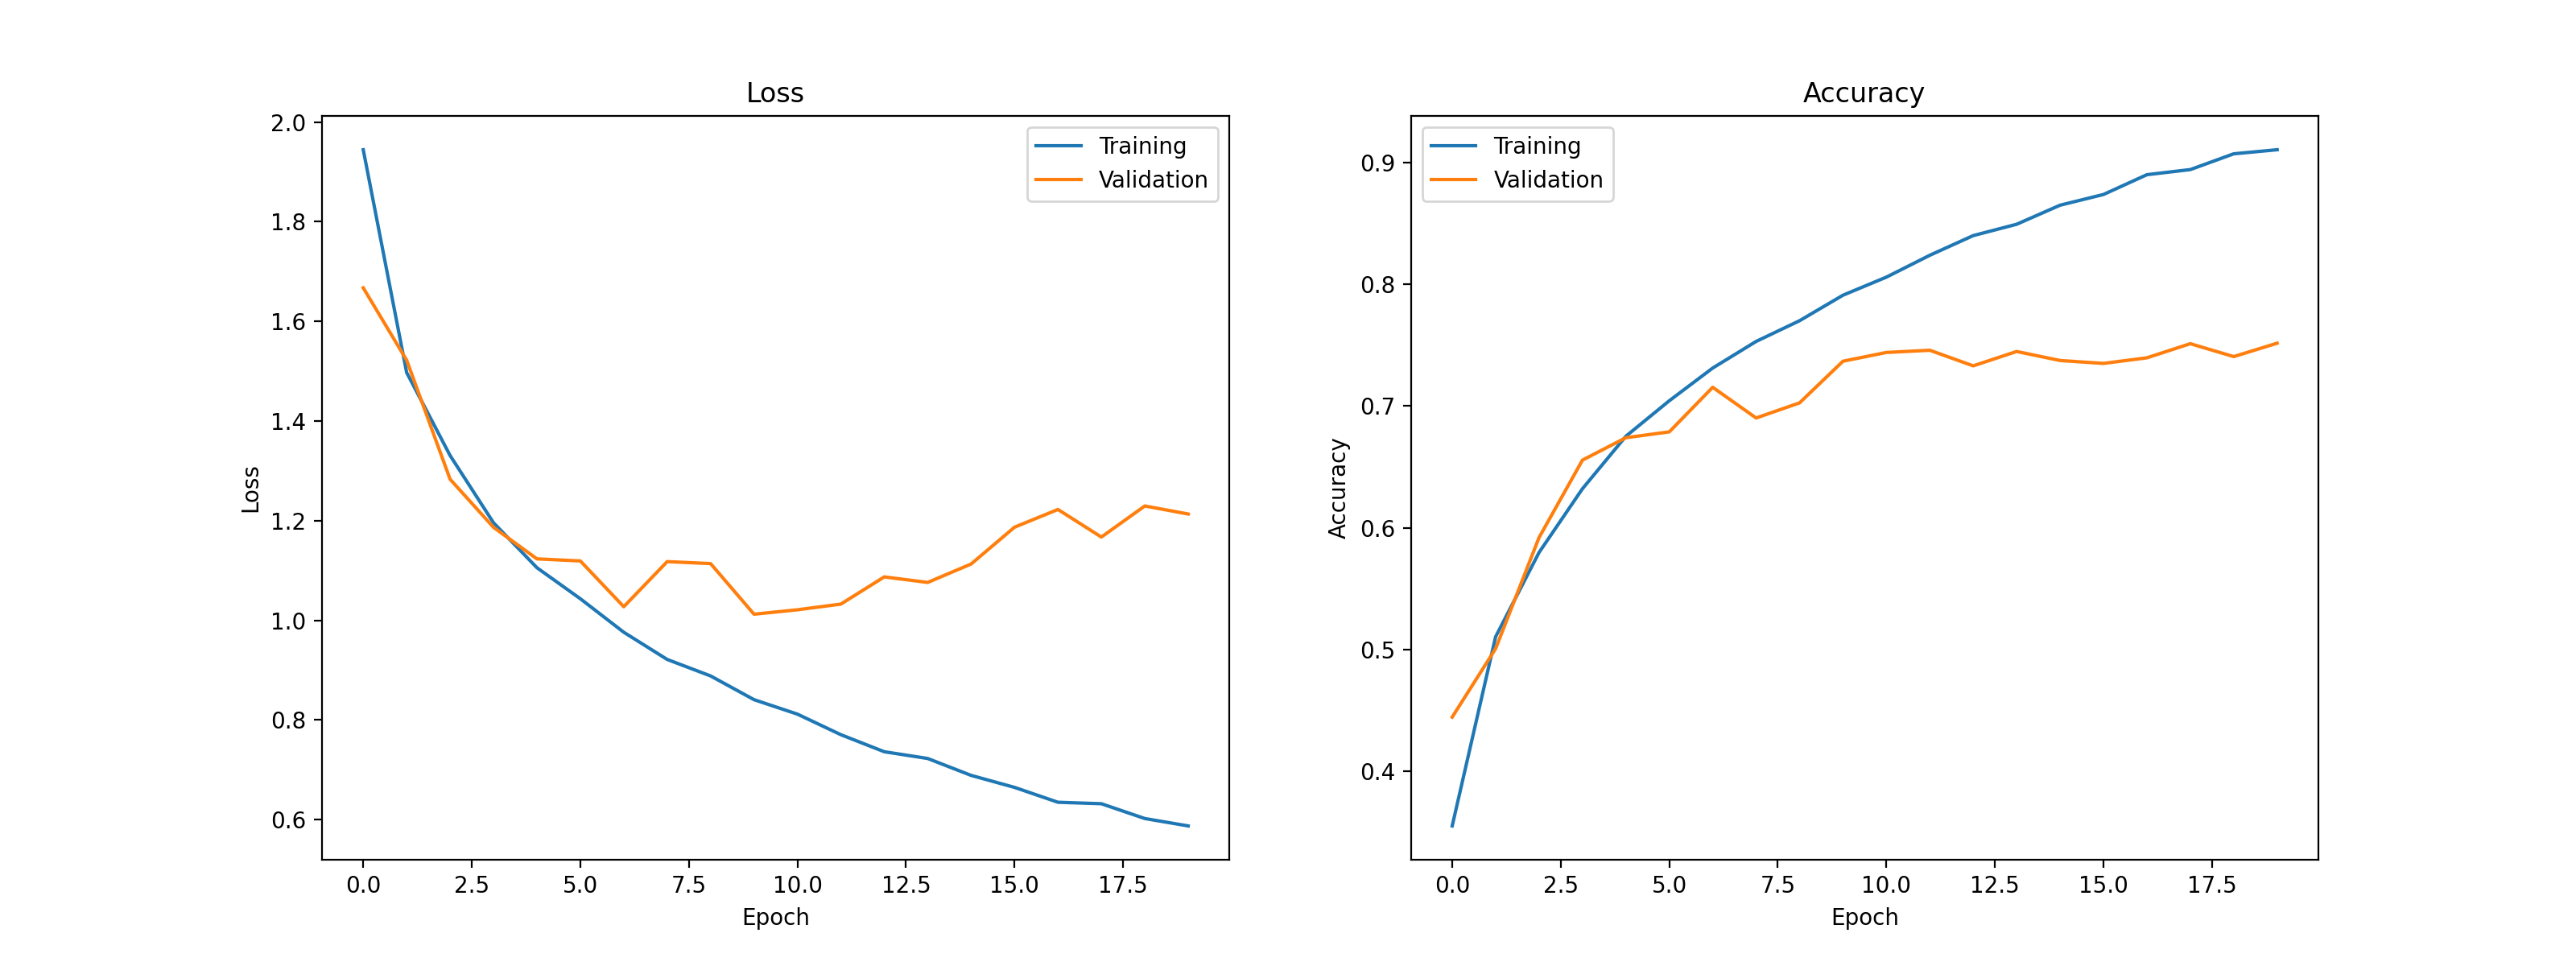

In [17]:
##### YOUR CODE STARTS #####
# plot the progress curves here
plot_curves(history)
##### YOUR CODE ENDS #####

In [18]:
##### YOUR CODE STARTS #####
# evaluate the model here
model.evaluate(X_test_norm, y_test)
##### YOUR CODE ENDS #####

313/313 [==============================] - 1s 4ms/step - loss: 1.2803 - accuracy: 0.7417


[1.2803477048873901, 0.7416999936103821]

<font color='red'> Your insightful interpretation of the results goes here: </font>

Model has a high accuracy ~0.9 on train data. However, the accuracy on validation is 0.74 . The dirrefence in accuracy is more than 10%, which clearly indicates that the model is overfitted.

## Homework exercise 3 (3 points): applying more sophisticated augmentation pipelines
<font color='red'> Check https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/image/ImageDataGenerator and add more interesting transformation into the pipeline we have developed in the class. Train your network again, and interpret the results. First of all some setup. </font>

In [5]:
# Keras comes with built-in loaders for common datasets
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

# shorten dataset for quicker training
X_train = X_train[:25000]
y_train = y_train[:25000]


<font color='red'> **(Homework exercise 3- a)** Add at least 2-3 more different transformations described at https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/image/ImageDataGenerator. Augment CIFAR10 training images. Visualise a few random augmentated images (as we have done for the simple augmentation pipeline in the class). This time, make 5 by 5 grid instead of 3 by 3. **(1 point)**. </font>


In [19]:
from keras.preprocessing.image import ImageDataGenerator

##### YOUR CODE STARTS #####
# Create your own data augmentation pipeline:
datagen = ImageDataGenerator(
    rotation_range=15, # randomly rotate an image from 0 to 15 degrees
    width_shift_range=0.1,  # horizontally shift an image by a fraction of 0% - 10% (of original width)
    height_shift_range=0.1, # vertically shift an image by a fraction of 0% - 10% (of original height)
    horizontal_flip=True,
    brightness_range = [0.5, 1.5],
    zoom_range = 0.1, # 10% zoom range [1-zoom_range, 1+zoom_range]
    shear_range = 0.1 # 10% Shear Intensity
    ) # horizontaly flip random 30% of images
##### YOUR CODE ENDS #####

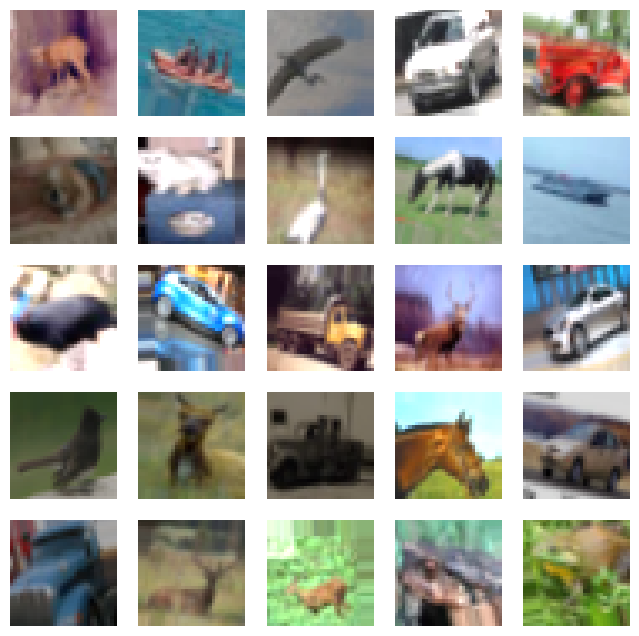

In [20]:
##### YOUR CODE STARTS #####
plt.rcParams['figure.figsize'] = (8.0, 8.0) # set default size of plots

# Configure batch size and retrieve one batch of images
for X_batch, y_batch in datagen.flow(X_train, y_train, batch_size=25):
    # Show 25 images
    for i in range(0, 25):
        plt.subplot(5, 5, 1 + i)
        plt.imshow(X_batch[i].astype('uint8'))
        plt.axis('off')
    # show the plot
    plt.show()
    break
##### YOUR CODE ENDS #####

<font color='red'> Here, briefly explain your choice of augmentation pipeline (i.e. why these augmentation you added will help?) </font>

<font color='red'> Your textual answer goes here: </font>

In addition to the augmentation pipeline discussed in the practice session, I added three more transformations: shear_range and zoom_range.

Each transformation has a modest value of 10%.

I selected these two transformations because the resulting image will still closely resemble a real-world image, unlike radical transformations such as vertical_flip.

Lastly, I added a brightness transformation. The reasoning is the same, it shouldn't create image which hard to find in a real world.

<font color='red'> **(Homework exercise 3- b)** First, split the training data into train and validation sets using `train_test_split` function from `sklearn` (use 10% for validation). Then normalise each of the three sets (train, val and test) using mean and standard deviations computed on train images (for R, G and B separately). Finally, retrain the model using this new augmented training set. Use non-augmented normalised validation set for validation of the model while training. **(1.5 points)**. </font>

In [21]:
from sklearn.model_selection import train_test_split

##### YOUR CODE STARTS #####
# Split the training data further into train and val
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, random_state = 111, test_size = 0.10)

mu = X_train.mean(axis=(0,1,2)) # finds mean of R, G and B separately
std = X_train.std(axis=(0,1,2)) # same for std
X_train_norm = (X_train - mu)/std
X_val_norm = (X_val - mu)/std
X_test_norm = (X_test - mu)/std
##### YOUR CODE ENDS #####

# Assign augmentation schema to X_train_norm
datagen.fit(X_train_norm)

In [25]:
##### YOUR CODE STARTS #####
from tensorflow.keras.utils import to_categorical
# Create a model
# here you can use either model with dropout or L2 regularisation defined above
model = define_model_dropout_lambda(0, 0.001) # lambda_optimal

# Compile the model as before (code is identical)
model.compile(loss='categorical_crossentropy', optimizer=optimizers.Adam(learning_rate=0.001), metrics=['accuracy'])

# remember to use .fit() to train the model
# use batch_size 64 as in the class
history_with_augment = model.fit(datagen.flow(X_train_norm, to_categorical(y_train), batch_size=64),
                    steps_per_epoch=X_train_norm.shape[0]//64, # number of steps per epochs, needs to be specified as we do augmentation
                    epochs=25,
                    verbose=1,
                    validation_data=(X_val_norm, to_categorical(y_val))
                    )

##### YOUR CODE ENDS #####

Epoch 1/25
351/351 [==============================] - 40s 80ms/step - loss: 2.0253 - accuracy: 0.3233 - val_loss: 1.6239 - val_accuracy: 0.4560
Epoch 2/25
351/351 [==============================] - 28s 79ms/step - loss: 1.6559 - accuracy: 0.4445 - val_loss: 1.4185 - val_accuracy: 0.5348
Epoch 3/25
351/351 [==============================] - 27s 77ms/step - loss: 1.5215 - accuracy: 0.5028 - val_loss: 1.3621 - val_accuracy: 0.5760
Epoch 4/25
351/351 [==============================] - 29s 83ms/step - loss: 1.4114 - accuracy: 0.5469 - val_loss: 1.3025 - val_accuracy: 0.5956
Epoch 5/25
351/351 [==============================] - 27s 78ms/step - loss: 1.3450 - accuracy: 0.5825 - val_loss: 1.2990 - val_accuracy: 0.5948
Epoch 6/25
351/351 [==============================] - 27s 77ms/step - loss: 1.2839 - accuracy: 0.6089 - val_loss: 1.0759 - val_accuracy: 0.6880
Epoch 7/25
351/351 [==============================] - 27s 78ms/step - loss: 1.2374 - accuracy: 0.6291 - val_loss: 1.0884 - val_accuracy:


<font color='red'> **(Homework exercise 3- c)** Plot the performance curves (loss and accuracy), evaluate your model on the non-augmented normalised test set and interpret the results. Did the performance improve? Why? Why not? **(0.5 points)**. </font>

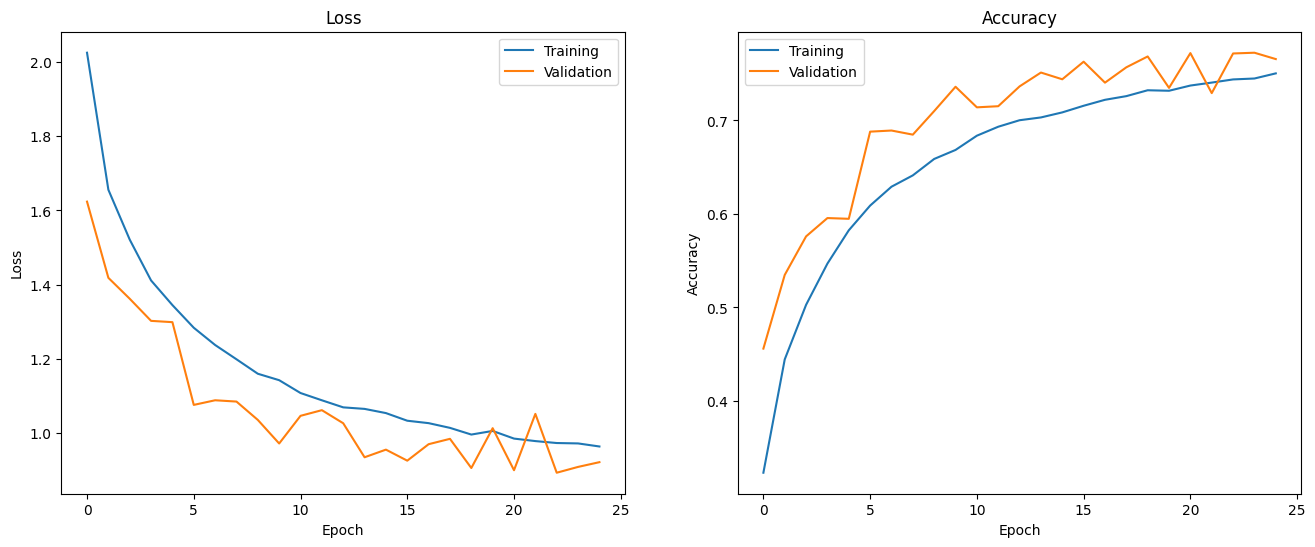

In [26]:
##### YOUR CODE STARTS #####
plot_curves(history_with_augment)
##### YOUR CODE ENDS #####

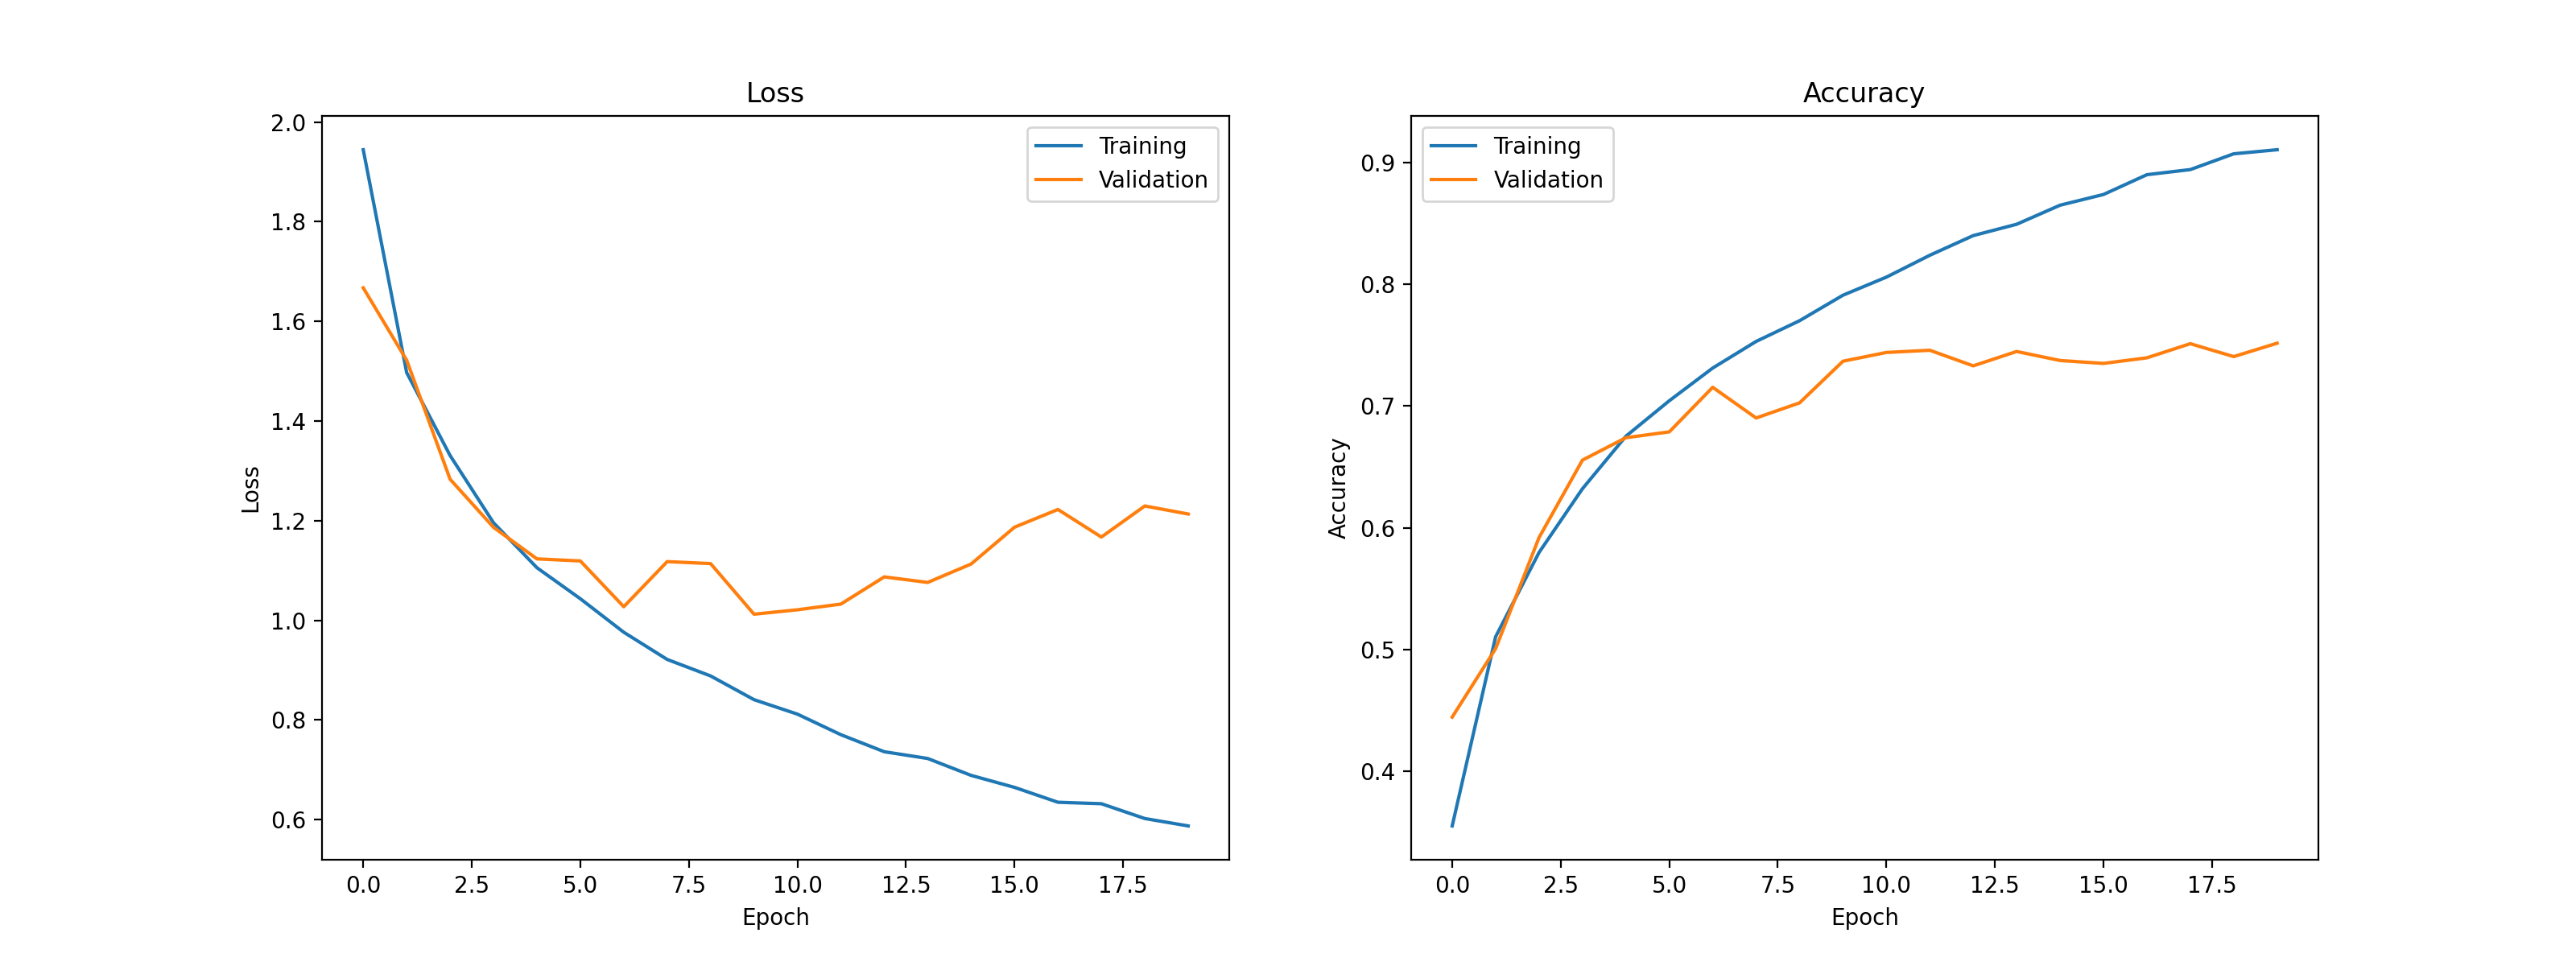

In [19]:
##### YOUR CODE STARTS #####
plot_curves(history)
##### YOUR CODE ENDS #####

<font color='red'> Textual answer to (**c**) goes here: </font>

A perfromance on validation data has improved. We've used an augmentation regularisation strategy. It "artificially" increases the size of the dataset.

Surprisingly, we observe a better performance on validation data than on the training data.

We assume that the culprit is the train/test split percentage.

Augmentation made the training dataset prevail over the validation set.

Probably the split now is 99%/1%, which may result in better accuracy for validation set.

In order to validate the assumption we can reduce the steps_per_epoch which will push the percentage of training data in a split down.

# Bonus exercises
*(NB, these are optional exercises!)*


## Implement CutMix from scratch (up to 4 bonus points depending on presentation):
<font color='red'> Experimentally verify if CutMix augmentation helps to improve the test score on CIFAR10 (not clear, as images are very tiny). Link to the CutMix paper: https://arxiv.org/abs/1905.04899. Implement and show couple of examples images augmented with CutMix. Test its performance and visualise the corresponding accuracy and loss curves. Compare the results of model trained on CutMix augmented images to the model trained without data augmentation. </font>


In [ ]:
##### YOUR CODE STARTS #####

##### YOUR CODE ENDS #####

In [ ]:
#Comparison part
##### YOUR CODE STARTS #####

##### YOUR CODE ENDS #####

<font color='red'> Your explanation: </font>

# Comments (optional feedback to the course instructors)
Here, please, leave your comments regarding the homework, possibly answering the following questions:
* how much time did you send on this homework?
* was it too hard/easy for you?
* what would you suggest to add or remove?
* anything else you would like to tell us